# Prototipo demostrable — Predicción de maniobras RAAD 2024

**Uso:** exposición del curso *Propuesta de Investigación*. Adaptación **single-view / frontal** basada en el dataset y el baseline del artículo **Gangisetty et al., ICPR 2024 Competition on Rider Intention Prediction**.

Esta versión permite: **cargar los ZIP reales → entrenar una GRU sobre embeddings VGG16 → evaluar → seleccionar un ejemplo real de validación → mostrar la maniobra predicha y las probabilidades → exportar resultados**.

> **Transparencia:** NO es una reproducción exacta de las métricas oficiales del artículo; es una *adaptación didáctica*. Las métricas se calculan en la partición oficial de **validación** (etiquetada), no en el conjunto de prueba oculto. **NO contiene archivos MP4 ni convierte el embedding en video**. Si tienes el MP4 real correspondiente a un ejemplo, puedes agregarlo opcionalmente para reproducirlo al lado de la predicción; el modelo sigue prediciendo desde sus embeddings VGG16, no desde un video arbitrario subido.

**Fuentes:** https://mobility.iiit.ac.in/icpr_2024_rip/dataset.html · https://github.com/wasilone11/ICPR-RIP-2024

## Instrucciones iniciales
1. En tu Google Drive crea `Mi unidad/Proyecto_RIP_2024`.
2. Sube a esa carpeta los **ZIP VGG16 de Training y Validation** que ya descargaste.
3. En Colab, menú **Entorno de ejecución → Ejecutar todas**, o ejecuta las celdas en orden.
4. Si quieres mostrar un MP4 *real de uno de los ejemplos*, guárdalo en `Proyecto_RIP_2024/videos` con el **mismo nombre base** que el archivo de features. El MP4 **no** viene en estos ZIP y no es obligatorio para la demostración.
5. Usa la última sección para seleccionar ejemplos y sacar capturas de pantalla de tus resultados **reales**.

In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 1. Conectar Google Drive y verificar dependencias

In [2]:
from google.colab import drive
from pathlib import Path
import os, io, re, json, random
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Video, clear_output

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/Proyecto_RIP_2024')
BASE.mkdir(parents=True, exist_ok=True)
OUT = BASE / 'resultados_prototipo'
OUT.mkdir(parents=True, exist_ok=True)
print('✅ Carpeta de datos:', BASE)
print('✅ Carpeta de resultados:', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Carpeta de datos: /content/drive/MyDrive/Proyecto_RIP_2024
✅ Carpeta de resultados: /content/drive/MyDrive/Proyecto_RIP_2024/resultados_prototipo


## 2. Identificar los ZIP de entrenamiento y validación

No descomprimas nada. El programa lee los archivos directamente desde los ZIP. Si el nombre de alguno es extraño, revisa los impresos en pantalla.

In [3]:
zips = sorted(BASE.glob('*.zip'))
for p in zips:
    print(f'ZIP: {p.name} ({p.stat().st_size / (1024**2):.1f} MiB)')
if len(zips) < 2:
    raise FileNotFoundError('Faltan ZIP. Sube los ZIP oficiales VGG16 Training y Validation a ' + str(BASE))

def elegir(claves):
    xs = [p for p in zips if any(k in p.name.lower() for k in claves)]
    if len(xs) != 1:
        raise ValueError('No pude elegir un único archivo para ' + str(claves)
                         + '\nZIP disponibles: ' + str([p.name for p in zips])
                         + '\nEdita ZIP_TRAIN y ZIP_VAL manualmente aquí.')
    return xs[0]

ZIP_TRAIN = elegir(['training', 'train'])
ZIP_VAL = elegir(['validation','valid','val_'])
print('Entrenamiento:', ZIP_TRAIN.name)
print('Validación:', ZIP_VAL.name)
for p in [ZIP_TRAIN, ZIP_VAL]:
    with ZipFile(p) as z:
        nombres = [x for x in z.namelist() if not x.endswith('/')]
        print('\n',p.name, '→', len(nombres),'archivos')
        print('Primeros archivos:')
        for x in nombres[:5]: print('  ',x)
        print('Extensiones:',sorted({Path(x).suffix.lower() for x in nombres}))

ZIP: VGG16_val_features.zip (213.6 MiB)
ZIP: vgg16_training_features.zip (481.7 MiB)
Entrenamiento: vgg16_training_features.zip
Validación: VGG16_val_features.zip

 vgg16_training_features.zip → 1500 archivos
Primeros archivos:
   VGG16_Training_Features/left_side_mirror_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy
   VGG16_Training_Features/left_side_mirror_view/Right Turn/8eb25ba4-0aa9-4f8e-9185-af08f122e719.npy
   VGG16_Training_Features/left_side_mirror_view/Right Turn/2bc0a583-7e79-4d4a-ad76-eaa884cbafb5.npy
   VGG16_Training_Features/left_side_mirror_view/Right Turn/5445621f-e73e-46de-bbf2-681c42901106.npy
   VGG16_Training_Features/left_side_mirror_view/Right Turn/fc7632e6-4d7b-4291-887d-beedf37f9df3.npy
Extensiones: ['.npy']

 VGG16_val_features.zip → 600 archivos
Primeros archivos:
   VGG16_val_features/left_side_mirror_view/Right Turn/8e376cf1-48dd-4cd6-b193-b3fd0dd60280.npy
   VGG16_val_features/left_side_mirror_view/Right Turn/49ab74ee-0433-4ec2-8cf1-5331034918f

## 3. Cargar los ejemplos de la cámara frontal

Este lector admite embeddings NumPy `.npy` o `.npz` de **512 características por instante**, guardados bajo las carpetas de vista y clase que describe el sitio oficial. Si el dataset descargado tiene otro formato, **no improvises etiquetas**: copia el error y revísalo con nosotros.

In [4]:
CLASES = ['Left Lane Change','Right Lane Change','Left Turn',
          'Right Turn','Slow-Stop','Straight']
ES = ['Cambio carril izquierda','Cambio carril derecha','Giro izquierda',
      'Giro derecha','Reducir velocidad / detenerse','Seguir recto']

def norma(x):
    return ' '.join(re.sub(r'[-_]+',' ',x.lower()).split())
MAPA = {norma(c):i for i,c in enumerate(CLASES)}
FRONTALES = {'frontal view', 'front view', 'frontal', 'front'}

def clase_vista(path):
    dirs = [norma(p) for p in Path(path).parts[:-1]]
    frontal = any(k in FRONTALES for k in dirs)
    clase = next((MAPA[k] for k in dirs if k in MAPA), None)
    return frontal, clase

def leer_vector_numpy(blob, nombre):
    ob = np.load(io.BytesIO(blob), allow_pickle=False)
    if isinstance(ob, np.lib.npyio.NpzFile):
        claves = list(ob.files)
        if not claves:
            raise ValueError('NPZ vacío: ' + nombre)
        ob = ob[claves[0]]
    x = np.asarray(ob, dtype=np.float32)
    if x.ndim == 1 and x.shape[0] == 512:
        x = x[None, :]
    elif x.ndim == 2 and x.shape[0] == 512 and x.shape[1] != 512:
        x = x.T
    elif x.ndim >= 3 and x.shape[-1] == 512:
        x = x.reshape(x.shape[0], -1, 512).mean(axis=1)
    if x.ndim != 2 or x.shape[-1] != 512:
        raise ValueError(f'Forma no compatible: {nombre}: {x.shape} (se esperaba T×512)')
    if x.shape[0] == 0 or not np.isfinite(x).all():
        raise ValueError('Embedding vacío o inválido: ' + nombre)
    return x

def cargar(p):
    muestras, etiquetas, nombres = [], [], []
    with ZipFile(p) as z:
        ficheros = [name for name in z.namelist() if name.lower().endswith(('.npy','.npz'))
                    and not name.startswith('__MACOSX/')]
        for name in ficheros:
            frontal, clase = clase_vista(name)
            if not frontal or clase is None: continue
            muestras.append(leer_vector_numpy(z.read(name),name))
            etiquetas.append(clase)
            nombres.append(Path(name).name)
    if not muestras:
        raise ValueError('Sin ejemplos frontales .npy/.npz en '+p.name+'. '
                         'Revisa carpetas y extensiones impresas en la celda anterior.')
    print(f'{p.name}: {len(muestras)} ejemplos frontales')
    print(pd.Series([CLASES[y] for y in etiquetas]).value_counts().to_string())
    print('Forma ejemplo:', muestras[0].shape)
    return muestras, np.asarray(etiquetas,dtype=np.int64), nombres

train_raw, y_train, nombres_train = cargar(ZIP_TRAIN)
val_raw, y_val, nombres_val = cargar(ZIP_VAL)
assert set(y_train) == set(range(6)), 'Falta alguna clase en Training.'
assert len(val_raw) > 0
print('✅ Datos cargados desde los ZIP oficiales.')

vgg16_training_features.zip: 500 ejemplos frontales
Left Turn            160
Right Turn           154
Straight              74
Slow-Stop             44
Right Lane Change     39
Left Lane Change      29
Forma ejemplo: (360, 512)
VGG16_val_features.zip: 200 ejemplos frontales
Straight             51
Right Turn           50
Left Turn            40
Slow-Stop            26
Left Lane Change     17
Right Lane Change    16
Forma ejemplo: (172, 512)
✅ Datos cargados desde los ZIP oficiales.


## 4. Preparar las series temporales

Seleccionamos hasta **20 instantes** equidistantes de cada ejemplo y estandarizamos con estadísticas calculadas **solo sobre Training**, evitando filtración de información de Validation.

In [5]:
LONGITUD = 20

def muestrear(x):
    if len(x) > LONGITUD:
        x = x[np.linspace(0,len(x)-1,LONGITUD).round().astype(int)]
    return x

train_sub = [muestrear(x) for x in train_raw]
val_sub = [muestrear(x) for x in val_raw]
matriz_train = np.concatenate(train_sub,axis=0)
media = matriz_train.mean(axis=0)
sigma = matriz_train.std(axis=0)
sigma[sigma < 1e-6] = 1.

def matriz(muestras):
    a = np.zeros((len(muestras), LONGITUD, 512),np.float32)
    for i,x in enumerate(muestras):
        a[i,:len(x),:] = (x-media)/sigma
    return a

X_train = matriz(train_sub)
X_val = matriz(val_sub)
print('Train:',X_train.shape,'Validation:',X_val.shape)
print('Ejemplos por clase en validación:')
print(pd.Series([CLASES[k] for k in y_val]).value_counts().to_string())

Train: (500, 20, 512) Validation: (200, 20, 512)
Ejemplos por clase en validación:
Straight             51
Right Turn           50
Left Turn            40
Slow-Stop            26
Left Lane Change     17
Right Lane Change    16


## 5. Entrenar el prototipo (VGG16 preextraído + GRU)

Usamos una variante pequeña de RNN, la **GRU**. A diferencia de las cifras del artículo, los resultados de esta sección serán **los que obtengas al ejecutar tu experimento**. Esto es una adaptación y NO el baseline oficial idéntico.

In [6]:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

keras.utils.set_random_seed(42)
modelo = keras.Sequential([
    keras.layers.Input(shape=(LONGITUD,512)),
    keras.layers.Masking(mask_value=0.0),
    keras.layers.GRU(16,return_sequences=True),
    keras.layers.GRU(8),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(8,activation='relu'),
    keras.layers.Dense(6,activation='softmax'),
])
modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
               loss='sparse_categorical_crossentropy',metrics=['accuracy'])
modelo.summary()

historial = modelo.fit(X_train,y_train,
    validation_data=(X_val,y_val), epochs=30,batch_size=16,verbose=1,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=6,
                                             restore_best_weights=True)])
print('✅ Modelo entrenado.')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 20, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 20, 16)         │        25,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 8)              │           624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            54 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,190 (102.30 KB)

 Trainable params: 26,190 (102.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.2140 - loss: 1.7630 - val_accuracy: 0.2800 - val_loss: 1.7683
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.3980 - loss: 1.5886 - val_accuracy: 0.2850 - val_loss: 1.6947
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4540 - loss: 1.4568 - val_accuracy: 0.3100 - val_loss: 1.6395
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5220 - loss: 1.3209 - val_accuracy: 0.3200 - val_loss: 1.5869
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5420 - loss: 1.2015 - val_accuracy: 0.3450 - val_loss: 1.5512
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.6560 - loss: 1.0268 - val_accuracy: 0.4150 - val_loss: 1.4747
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.7100 - loss: 0.9100 - val_accuracy: 0.4000 - val_loss: 1.4807
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7460 - loss: 0.7802 - val_accuracy: 0.4650 - v

## 6. Evaluar y guardar evidencias de experimentación

ACCURACY VALIDACIÓN: 47.00%
F1-MACRO VALIDACIÓN: 33.43%
                   precision    recall  f1-score   support

 Left Lane Change       0.40      0.12      0.18        17
Right Lane Change       0.18      0.12      0.15        16
        Left Turn       0.51      0.78      0.61        40
       Right Turn       0.62      0.74      0.67        50
        Slow-Stop       0.00      0.00      0.00        26
         Straight       0.35      0.43      0.39        51

         accuracy                           0.47       200
        macro avg       0.34      0.36      0.33       200
     weighted avg       0.39      0.47      0.42       200



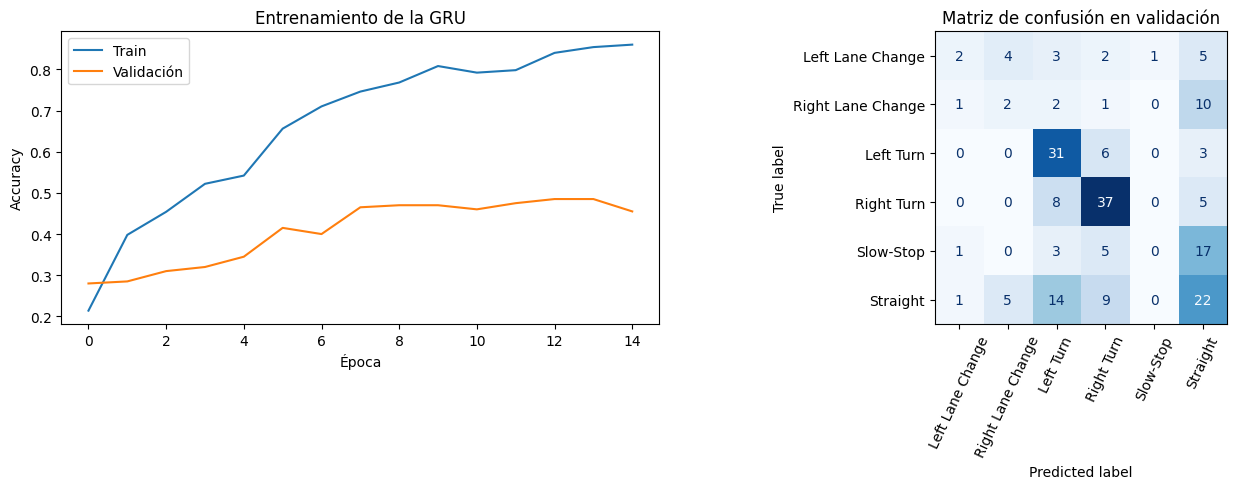

✅ Evidencias guardadas en Drive: /content/drive/MyDrive/Proyecto_RIP_2024/resultados_prototipo
 - evaluacion_raad.png, modelo_raad_gru.keras, predicciones_validacion.csv y resumen.txt


In [7]:
probs = modelo.predict(X_val,verbose=0)
preds = np.argmax(probs,axis=1)
ACC = accuracy_score(y_val,preds)
F1 = f1_score(y_val,preds,average='macro',zero_division=0)
cm = confusion_matrix(y_val,preds,labels=np.arange(6))
print(f'ACCURACY VALIDACIÓN: {ACC*100:.2f}%')
print(f'F1-MACRO VALIDACIÓN: {F1*100:.2f}%')
print(classification_report(y_val,preds,labels=np.arange(6),target_names=CLASES,zero_division=0))

fig,axes = plt.subplots(1,2,figsize=(14,5))
axes[0].plot(historial.history['accuracy'],label='Train')
axes[0].plot(historial.history['val_accuracy'],label='Validación')
axes[0].set(xlabel='Época',ylabel='Accuracy',title='Entrenamiento de la GRU')
axes[0].legend()
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm,display_labels=CLASES).plot(
    ax=axes[1],xticks_rotation=65,colorbar=False,cmap='Blues')
axes[1].set_title('Matriz de confusión en validación')
fig.tight_layout()
fig.savefig(OUT/'evaluacion_ra​ad.png'.replace('​',''),dpi=170,bbox_inches='tight')
plt.show()

modelo.save(str(OUT/'modelo_raad_gru.keras'))
np.savez_compressed(OUT/'normalizacion.npz',media=media,sigma=sigma,longitud=LONGITUD)
reporte = pd.DataFrame({'archivo':nombres_val,
                        'clase_real':[CLASES[k] for k in y_val],
                        'prediccion':[CLASES[k] for k in preds],
                        'correcto':preds == y_val})
for i,clase in enumerate(CLASES): reporte['p_'+clase] = probs[:,i]
reporte.to_csv(OUT/'predicciones_validacion.csv',index=False)
(OUT/'resumen.txt').write_text(
    f'RAAD 2024 — adaptación didáctica VGG16 + GRU (single-view)\n'
    f'Train: {len(y_train)}; Validation: {len(y_val)}\n'
    f'Accuracy validación: {ACC:.4f} ({ACC*100:.2f}%)\n'
    f'F1 macro validación: {F1:.4f} ({F1*100:.2f}%)\n'
    f'No comparable directamente con test oficial oculto.\n',encoding='utf-8')
print('✅ Evidencias guardadas en Drive:',OUT)
print(' - evaluacion_raad.png, modelo_raad_gru.keras, predicciones_validacion.csv y resumen.txt')

## 7. Demostración INTERACTIVA para el profesor 🎬

1. Selecciona uno de los **ejemplos reales de Validation**.
2. Presiona **🔎 Predecir maniobra**. Verás la **clase verdadera**, la **predicción del modelo**, las **probabilidades** y una gráfica temporal de características.
3. Usa **🎲 Otro ejemplo** para mostrar que no es una captura estática.
4. **Opcional:** si tienes un MP4 auténtico que corresponda al mismo identificador, colócalo en la subcarpeta `videos` dentro de `Proyecto_RIP_2024`. Aparecerá como reproducción vinculada; de lo contrario se mostrará un aviso. No se infiere un MP4 directamente, se predicen embeddings asociados a él.

La barra más alta es la salida estimada por el modelo, **no una certeza clínica o vial calibrada**.

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output, Video

selector = widgets.Dropdown(
    options=[(f'{i+1:03d} | {Path(n).stem[:36]} | {ES[y_val[i]]}',i)
             for i,n in enumerate(nombres_val)],
    description='Ejemplo:',layout=widgets.Layout(width='95%'))
boton = widgets.Button(description='🔎 Predecir maniobra',button_style='primary')
azar = widgets.Button(description='🎲 Otro ejemplo')
salida = widgets.Output()

# Se exige la coincidencia del nombre base para no presentar un video distinto como si fuera el del ejemplo.
def buscar_video_original(nombre):
    carpeta = BASE/'videos'
    if not carpeta.is_dir(): return None
    stem = Path(nombre).stem.lower()
    candidatos = [p for p in carpeta.rglob('*') if p.is_file()
                  and p.suffix.lower() in {'.mp4','.mov','.avi','.webm'}
                  and p.stem.lower() == stem]
    return candidatos[0] if len(candidatos) == 1 else None

def mostrar_ejemplo(_=None):
    i = selector.value
    p = probs[i]
    pred = int(np.argmax(p))
    real = int(y_val[i])
    with salida:
        clear_output(wait=True)
        color = '#15803d' if pred==real else '#b91c1c'
        display(HTML(f'<div style="font-family:Arial,sans-serif;border:2px solid #e5e7eb;'
                  f'padding:20px;border-radius:15px;max-width:950px">'
                  f'<h2 style="margin:0">🏍️ DEMO RAAD · VISTA FRONTAL</h2>'
                  f'<p><b>Archivo:</b> {Path(nombres_val[i]).name}</p>'
                  f'<p><b>Maniobra real:</b> {ES[real]}</p>'
                  f'<p style="font-size:21px;color:{color}"><b>Predicción: {ES[pred]}</b></p>'
                  f'<p><b>Coincidencia:</b> {"CORRECTA ✅" if pred==real else "INCORRECTA ❌"}'
                  f' &nbsp; | &nbsp; <b>Probabilidad mayor:</b> {float(p.max()):.1%}</p>'
                  f'</div>'))
        fig,axs = plt.subplots(1,2,figsize=(12,4))
        order = np.argsort(p)
        axs[0].barh([ES[j] for j in order],p[order])
        axs[0].set_xlim(0,1)
        axs[0].set_xlabel('Salida softmax (no calibrada)')
        axs[0].set_title('Probabilidades de las seis maniobras')
        axs[1].plot(np.linalg.norm(val_sub[i],axis=1),marker='o',markersize=3)
        axs[1].set(xlabel='Instante de característica muestreada',
                   ylabel='Norma de embedding',title='Secuencia visual: representación numérica')
        fig.tight_layout()
        plt.show()
        vid = buscar_video_original(nombres_val[i])
        if vid:
            display(HTML('<b>Video ORIGINAL vinculado por nombre exacto:</b>'))
            display(Video(str(vid),embed=True,width=550))
        else:
            display(HTML('<p style="color:#92400e">🎬 Video no disponible. '
                         'Los ZIP VGG16 contienen datos numéricos, no fotogramas MP4. '
                         'Esta predicción sí se realiza sobre un ejemplo real del dataset.</p>'))

def otro(_):
    selector.value = random.randrange(len(nombres_val))
    mostrar_ejemplo()

boton.on_click(mostrar_ejemplo)
azar.on_click(otro)
display(widgets.VBox([HTML('<h2>Prototipo interactivo: clasificación de maniobras</h2>'),
                     selector,widgets.HBox([boton,azar]),salida]))
mostrar_ejemplo()

## 8. Checklist para la presentación

✅ Si llegaste hasta aquí y la demo apareció, ya tienes un **prototipo funcional basado en los embeddings reales** de RAAD.

**Qué mostrar (Diapositiva 2):** captura de la **demo**, gráfico **Accuracy/matriz de confusión**, cifras **reales** del archivo `resumen.txt` y un enlace a **tu propio GitHub** con el notebook.

**Guion de 20 segundos para la demo:** «Este prototipo fue entrenado con las características VGG16 del dataset RAAD, utilizando únicamente la cámara frontal. Seleccionamos un ejemplo de validación que el modelo no utilizó para ajustar sus parámetros y vemos la maniobra que predice, la clase real y sus probabilidades. Además, calculamos Accuracy y F1-macro sobre el conjunto de validación. Nuestro experimento es una adaptación didáctica, no una réplica exacta de los resultados del test de la competición».

**Aclaración sobre videos:** reproducir los MP4 originales solo es posible si consigues esos archivos por separado. **No afirmes que el sistema reconoce cualquier MP4**: esta implementación trabaja con *embeddings* preextraídos.

**Sobre GitHub:** puedes subir este `.ipynb`, capturas y `resumen.txt` (sin subir datos pesados ni tus credenciales de Drive).